# 10 · Linear basis light curves

**Level:** advanced · **Prerequisites:** [03](03_first_fit.ipynb), [07](07_how_pizzetti_computes_a_light_curve.ipynb) · **Run time:** ~20 s

**Covers:** `occult_terms`, `quadratic_from_terms`, the power basis 1, μ, μ², linear least squares for limb darkening and baseline, many wavelength channels at once

For the quadratic family the flux is *linear* in the intensity coefficients. `occult_terms(z, rp)` returns the three
geometry-only terms in one pass; any quadratic-family light curve, and any linear fit of its coefficients, follows
from them by a few multiply–adds. This is the machinery behind `MarginalTransitModel`, and it is useful on its own,
for example for transmission spectra with hundreds of wavelength channels.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
import pizzetti
from pizzetti import occult, occult_terms, quadratic_from_terms

## 1. Three terms, every coefficient set

`occult_terms` returns `T = (lex, ldx, edx)`, each of the shape of `z`. For quadratic coefficients `u`,
`quadratic_from_terms(T, u)` gives the flux.

In [2]:
rp = 0.1
z = np.linspace(0, 1.2, 50_000)
T = occult_terms(z, rp)
for u in ([0.0, 0.0], [0.6, 0.0], [0.4, 0.25], [0.2, 0.5]):
    d = np.max(np.abs(quadratic_from_terms(T, u) - occult(z, rp, u, "quadratic")))
    print(f"u = {u}: |terms - occult| = {d:.1e}")
s = time.perf_counter(); T = occult_terms(z, rp); t_terms = time.perf_counter() - s
s = time.perf_counter()
for u in np.random.default_rng(0).uniform(0, 0.4, (100, 2)):
    occult(z, rp, u, "quadratic")
t_occ = (time.perf_counter() - s) / 100
s = time.perf_counter()
for u in np.random.default_rng(0).uniform(0, 0.4, (100, 2)):
    quadratic_from_terms(T, u)
t_lin = (time.perf_counter() - s) / 100
print(f"occult_terms once: {1e3 * t_terms:.2f} ms;  per coefficient set: occult {1e3 * t_occ:.2f} ms, from the terms {1e3 * t_lin:.2f} ms")

u = [0.0, 0.0]: |terms - occult| = 0.0e+00
u = [0.6, 0.0]: |terms - occult| = 7.1e-10
u = [0.4, 0.25]: |terms - occult| = 7.2e-10
u = [0.2, 0.5]: |terms - occult| = 7.3e-10
occult_terms once: 0.70 ms;  per coefficient set: occult 0.27 ms, from the terms 0.11 ms


## 2. The power basis

For an intensity I(μ) = a₀ + a₁μ + a₂μ² the blocked flux, in units of π, is

  a₀·lex + a₁·ldx + a₂·(lex − edx),

and the unocculted flux is π(a₀ + 2a₁/3 + a₂/2). A light curve with a free baseline is therefore a linear
combination of three columns, one per power of μ.

In [3]:
def design(T):
    lex, ldx, edx = T
    return np.column_stack([1 - lex, 2 / 3 - ldx, 0.5 - (lex - edx)])    # unocculted minus blocked, per basis function

def to_quadratic(a):
    tot = a.sum()                                    # I(1)
    u2 = -a[2] / tot
    u1 = a[1] / tot - 2 * u2
    return u1, u2, (a[0] + 2 * a[1] / 3 + a[2] / 2)  # u1, u2 and the baseline (unocculted flux / pi)

# check: a quadratic star with baseline 1
u1, u2 = 0.4, 0.25
a = np.array([1 - u1 - u2, u1 + 2 * u2, -u2]) / (1 - u1 / 3 - u2 / 6)
print("max |A a - occult| =", np.max(np.abs(design(T) @ a - occult(z, rp, [u1, u2], "quadratic"))))

max |A a - occult| = 7.226353959666199e-10


## 3. Limb darkening by linear least squares

At a fixed geometry, the best limb darkening and baseline follow from one linear solve, with no iteration and no
starting guess.

In [4]:
p = pizzetti.TransitParams()
p.t0, p.per, p.rp, p.a, p.inc, p.ecc, p.w, p.limb_dark, p.u = 0.0, 3.5, 0.1, 9.0, 87.8, 0.0, 90.0, "quadratic", [0.4, 0.25]
t = (np.arange(7)[:, None] * 3.5 + np.arange(-0.13, 0.13, 2.0 / 1440)[None, :]).ravel()
m = pizzetti.TransitModel(p, t)
sigma = 500e-6
y = 1.0003 * m.light_curve(p) + sigma * np.random.default_rng(1).standard_normal(t.size)

A = design(occult_terms(m.ds, p.rp))
a_hat, *_ = np.linalg.lstsq(A, y, rcond=None)
cov = np.linalg.inv(A.T @ A) * sigma**2
draws = np.random.default_rng(2).multivariate_normal(a_hat, cov, 4000)
q = np.array([to_quadratic(x) for x in draws])
for i, n in enumerate(["u1", "u2", "baseline"]):
    print(f"{n:8s} {np.median(q[:, i]):.6f} ± {q[:, i].std():.6f}")
print("(truth: u1 = 0.4, u2 = 0.25, baseline 1.0003)")

u1       0.396268 ± 0.035916
u2       0.253208 ± 0.052049
baseline 1.000282 ± 0.000014
(truth: u1 = 0.4, u2 = 0.25, baseline 1.0003)


## 4. Many wavelength channels

A transmission spectrum fits the same transit in many wavelength channels, each with its own radius ratio and
limb darkening. With the geometry fixed (from the white light curve), each channel is a 1-D problem in `rp`: for every
trial `rp` the limb darkening and baseline are a linear solve. Here: 200 channels.

200 channels x 23 radius ratios in 0.2 s


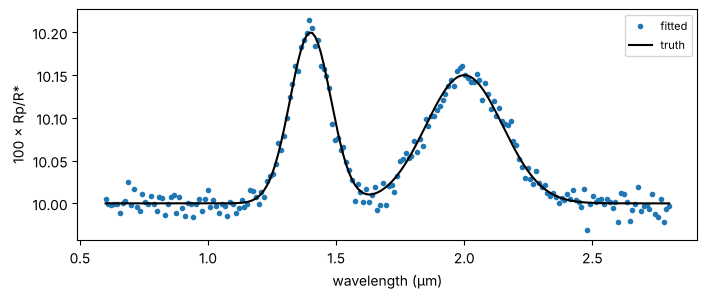

In [5]:
rng = np.random.default_rng(3)
nchan = 200
wl = np.linspace(0.6, 2.8, nchan)                                     # microns
rp_true = 0.1 + 0.002 * np.exp(-0.5 * ((wl - 1.4) / 0.08)**2) + 0.0015 * np.exp(-0.5 * ((wl - 2.0) / 0.15)**2)
u_true = np.column_stack([0.5 - 0.12 * wl, 0.2 + 0.0 * wl])
Y = np.empty((nchan, t.size))
for i in range(nchan):
    p.rp, p.u = rp_true[i], list(u_true[i])
    Y[i] = m.light_curve(p) + 300e-6 * rng.standard_normal(t.size)

def chi2_profile(rp, y):
    A = design(occult_terms(m.ds, rp))
    a, res, *_ = np.linalg.lstsq(A, y, rcond=None)
    return float(res[0]) if res.size else float(np.sum((y - A @ a)**2))

grid = np.linspace(0.095, 0.106, 23)
s = time.perf_counter()
rp_fit = np.empty(nchan)
for i in range(nchan):
    c = np.array([chi2_profile(r, Y[i]) for r in grid])
    j = int(np.clip(np.argmin(c), 1, len(grid) - 2))
    x0, x1, x2 = grid[j - 1:j + 2]; c0, c1, c2 = c[j - 1:j + 2]
    rp_fit[i] = x1 - 0.5 * ((x1 - x0)**2 * (c1 - c2) - (x1 - x2)**2 * (c1 - c0)) / ((x1 - x0) * (c1 - c2) - (x1 - x2) * (c1 - c0))
print(f"{nchan} channels x {grid.size} radius ratios in {time.perf_counter() - s:.1f} s")
plt.figure(figsize=(8, 3))
plt.plot(wl, 1e2 * rp_fit, ".", label="fitted"); plt.plot(wl, 1e2 * rp_true, "k", label="truth")
plt.xlabel("wavelength (µm)"); plt.ylabel("100 × Rp/R*"); plt.legend(fontsize=8);

## What you learned

- `occult_terms` gives three geometry-only terms; `quadratic_from_terms` turns them into any quadratic-family light curve.
- In the power basis 1, μ, μ² the light curve is linear in the coefficients, so limb darkening and baseline follow from a least-squares solve.
- Profiling one nonlinear parameter over linear ones handles hundreds of channels in seconds.

**Next:** [J1 · Julia quickstart](../julia/examples/J1_quickstart.jl) or [the paper reproduction](paper/)